# 📊 Delay-to-Dollars: Exploratory Data Analysis

**Objective**: Profile the operational dataset, uncover patterns in delivery delays, stockouts, and revenue leakage, and quantify the financial impact of operational bottlenecks.

**Author**: Sharan Biradar  
**Date**: October 2026  
**Dataset**: 500 transactions across 4 regions, 15 products, 30 customers (Jan–Dec 2025)

In [1]:
# ============================================================
# SETUP & IMPORTS
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Style configuration
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'

COLORS = {
    'primary': '#1B2838',
    'accent': '#E63946',
    'success': '#2A9D8F',
    'warning': '#E9C46A',
    'info': '#457B9D',
    'light': '#F1FAEE'
}

print('✅ Libraries loaded successfully')

✅ Libraries loaded successfully


---
## 1. Data Loading & Initial Profiling

In [2]:
# Load all sheets from the Excel workbook
excel_path = '../operational_intelligence_dataset.xlsx'

sales = pd.read_excel(excel_path, sheet_name='Sales_Fact')
products = pd.read_excel(excel_path, sheet_name='Product_Dim')
customers = pd.read_excel(excel_path, sheet_name='Customer_Dim')
warehouses = pd.read_excel(excel_path, sheet_name='Warehouse_Dim')

print(f'Sales_Fact:    {sales.shape[0]:>4} rows × {sales.shape[1]} cols')
print(f'Product_Dim:   {products.shape[0]:>4} rows × {products.shape[1]} cols')
print(f'Customer_Dim:  {customers.shape[0]:>4} rows × {customers.shape[1]} cols')
print(f'Warehouse_Dim: {warehouses.shape[0]:>4} rows × {warehouses.shape[1]} cols')

Sales_Fact:     500 rows × 21 cols
Product_Dim:     15 rows × 5 cols
Customer_Dim:    30 rows × 4 cols
Warehouse_Dim:    4 rows × 3 cols


In [3]:
# Create enriched master dataset by joining all dimension tables
df = (
    sales
    .merge(products, on='Product_ID', how='left')
    .merge(customers, on='Customer_ID', how='left')
    .merge(warehouses, on='Warehouse_ID', how='left', suffixes=('', '_wh'))
)

# Parse dates and extract time features
df['Order_Date'] = pd.to_datetime(df['Order_Date'])
df['Month'] = df['Order_Date'].dt.month
df['Month_Name'] = df['Order_Date'].dt.strftime('%b')
df['Quarter'] = df['Order_Date'].dt.quarter
df['Day_of_Week'] = df['Order_Date'].dt.day_name()
df['Week_Number'] = df['Order_Date'].dt.isocalendar().week.astype(int)

print(f'✅ Master dataset created: {df.shape[0]} rows × {df.shape[1]} cols')
df.head(3)

✅ Master dataset created: 500 rows × 35 cols


,Order_ID,Order_Date,Region,Warehouse_ID,Sales_Rep,Customer_ID,Product_ID,Quantity,Gross_Sales,Discount_Pct,...,Customer_Name,Customer_Segment,Channel,Warehouse_Name,Region_wh,Month,Month_Name,Quarter,Day_of_Week,Week_Number
0,O0126,2025-01-02,West,W01,F. Adeyemi,C018,P08,7,64.4,0.02,...,Golden Basket,Retail,Traditional Trade,Lagos Central DC,West,1,Jan,1,Thursday,1
1,O0313,2025-01-02,East,W04,F. Adeyemi,C004,P11,7,17.5,0.04,...,Urban Basket,Key Account,Modern Trade,Enugu Hub,East,1,Jan,1,Thursday,1
2,O0380,2025-01-02,North,W02,F. Adeyemi,C030,P06,4,88.0,0.12,...,Prime Route,Distributor,Distributor,Abuja Hub,North,1,Jan,1,Thursday,1


In [4]:
# ============================================================
# DATA QUALITY REPORT
# ============================================================
print('=' * 60)
print('DATA QUALITY REPORT')
print('=' * 60)

# Missing values
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
quality_df = pd.DataFrame({
    'Column': df.columns,
    'Dtype': df.dtypes.values,
    'Non-Null': df.notnull().sum().values,
    'Missing': missing.values,
    'Missing %': missing_pct.values,
    'Unique': df.nunique().values
})

print(f'\n📋 Total Records: {len(df)}')
print(f'📋 Total Columns: {len(df.columns)}')
print(f'📋 Missing Values: {missing.sum()} ({missing.sum()/len(df)/len(df.columns)*100:.4f}%)')
print(f'📋 Duplicate Rows: {df.duplicated().sum()}')
print(f'📋 Date Range: {df["Order_Date"].min().date()} → {df["Order_Date"].max().date()}')

quality_df[quality_df['Missing'] > 0] if missing.sum() > 0 else print('\n✅ No missing values detected!')

DATA QUALITY REPORT

📋 Total Records: 500
📋 Total Columns: 35
📋 Missing Values: 0 (0.0000%)
📋 Duplicate Rows: 0
📋 Date Range: 2025-01-02 → 2025-12-30

✅ No missing values detected!


In [5]:
# Descriptive statistics for numerical columns
numeric_cols = ['Quantity', 'Gross_Sales', 'Discount_Pct', 'Discount_Amount',
                'Net_Sales', 'COGS', 'Profit', 'Profit_Margin_Pct',
                'Delivery_Days', 'Stock_On_Hand', 'Reorder_Level', 'Lost_Sales_Estimate']

desc = df[numeric_cols].describe().round(2)
desc.loc['skew'] = df[numeric_cols].skew().round(2)
desc.loc['kurtosis'] = df[numeric_cols].kurtosis().round(2)
desc

,Quantity,Gross_Sales,Discount_Pct,Discount_Amount,Net_Sales,COGS,Profit,Profit_Margin_Pct,Delivery_Days,Stock_On_Hand,Reorder_Level,Lost_Sales_Estimate
count,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00
mean,21.00,207.89,0.05,13.43,194.46,126.42,68.04,0.37,3.59,91.93,52.56,40.19
std,17.86,213.92,0.03,17.98,197.63,131.03,67.37,0.08,1.36,54.81,19.12,150.15
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,20.00,0.00
25%,8.00,65.00,0.03,1.75,64.38,40.70,23.84,0.33,3.00,56.75,40.00,0.00
50%,14.00,130.90,0.04,5.10,123.30,79.20,46.10,0.36,4.00,85.00,45.00,0.00
75%,31.00,289.85,0.08,18.00,271.27,178.84,92.58,0.39,5.00,127.00,80.00,0.00
max,82.00,1518.00,0.12,106.26,1411.74,931.50,480.24,0.56,8.00,256.00,80.00,1207.14
skew,1.22,2.23,0.37,2.08,2.26,2.21,2.35,-0.77,-0.02,0.38,0.41,4.81
kurtosis,0.73,7.13,-0.61,4.88,7.36,7.09,7.77,7.63,-0.20,-0.11,-1.13,25.65


---
## 2. Revenue Distribution Analysis

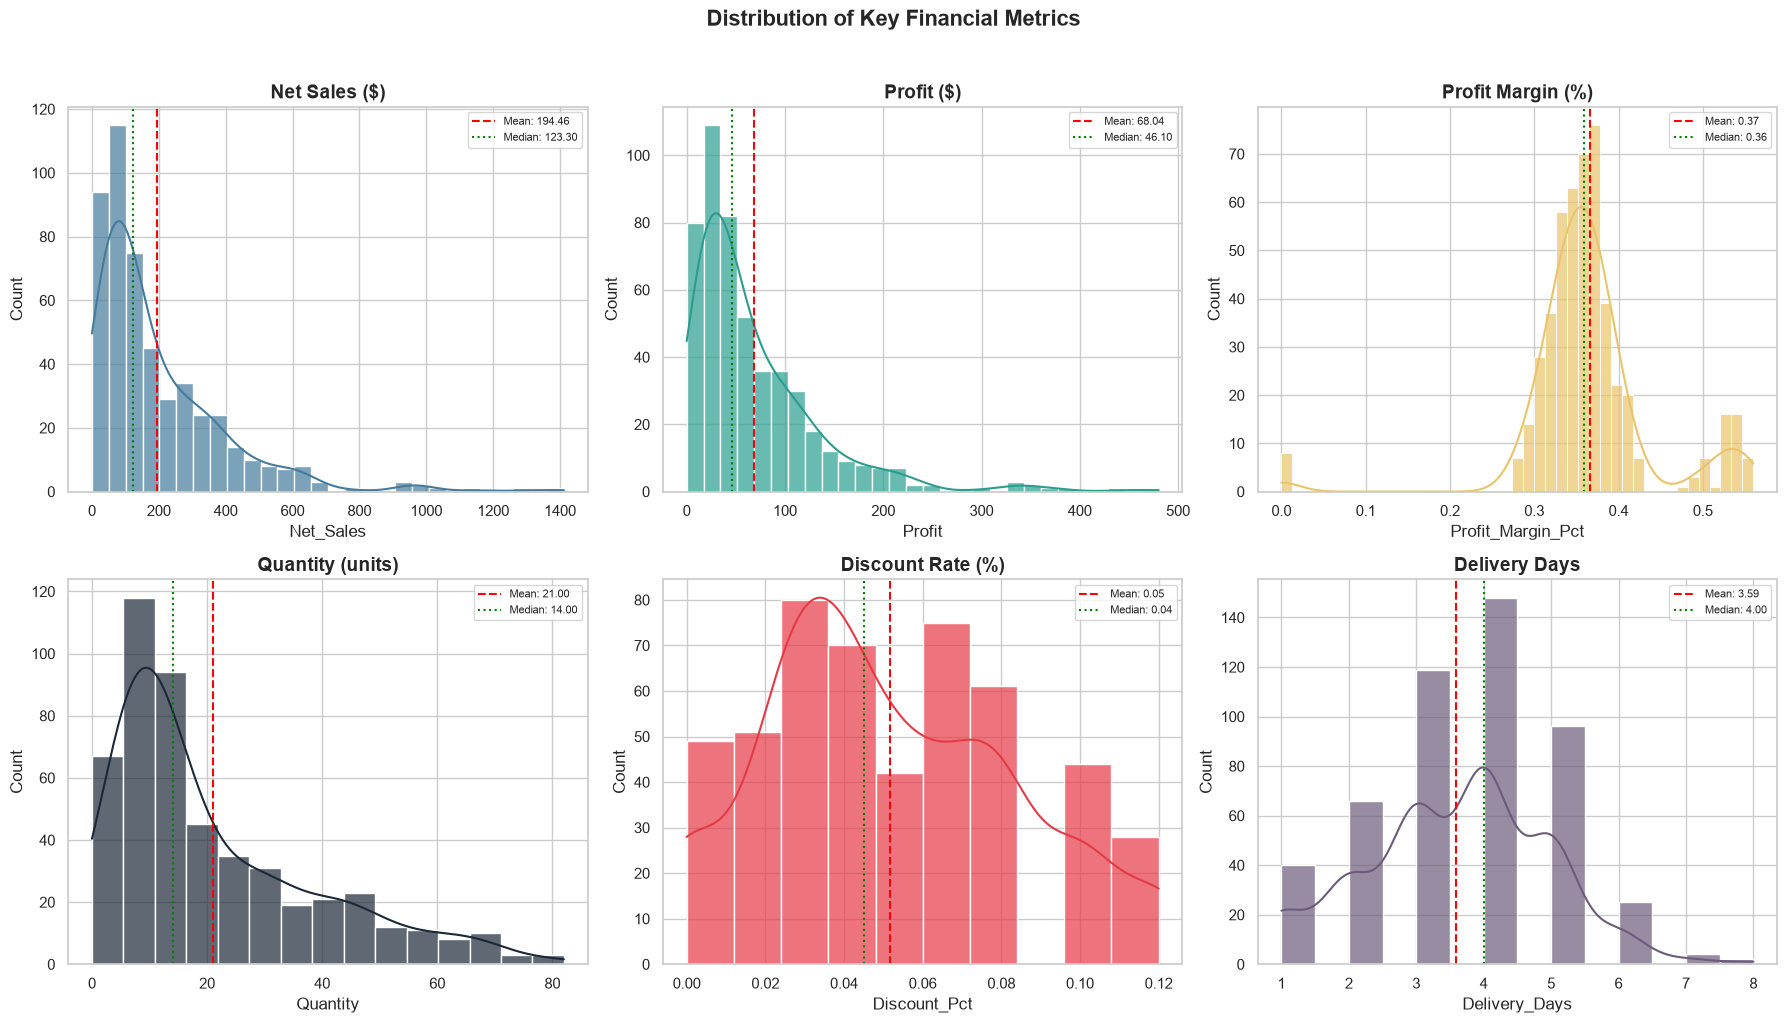

💡 Insight: Right-skewed distributions in Net Sales and Profit suggest a few high-value transactions drive revenue.


In [6]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Distribution of Key Financial Metrics', fontsize=16, fontweight='bold', y=1.02)

metrics = [
    ('Net_Sales', 'Net Sales ($)', COLORS['info']),
    ('Profit', 'Profit ($)', COLORS['success']),
    ('Profit_Margin_Pct', 'Profit Margin (%)', COLORS['warning']),
    ('Quantity', 'Quantity (units)', COLORS['primary']),
    ('Discount_Pct', 'Discount Rate (%)', COLORS['accent']),
    ('Delivery_Days', 'Delivery Days', '#6C5B7B')
]

for ax, (col, title, color) in zip(axes.flat, metrics):
    sns.histplot(df[col], kde=True, ax=ax, color=color, alpha=0.7, edgecolor='white')
    ax.axvline(df[col].mean(), color='red', linestyle='--', linewidth=1.5, label=f'Mean: {df[col].mean():.2f}')
    ax.axvline(df[col].median(), color='green', linestyle=':', linewidth=1.5, label=f'Median: {df[col].median():.2f}')
    ax.set_title(title)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig('../reports/figures/distributions.png', dpi=150, bbox_inches='tight')
plt.show()
print('💡 Insight: Right-skewed distributions in Net Sales and Profit suggest a few high-value transactions drive revenue.')

---
## 3. Correlation Analysis

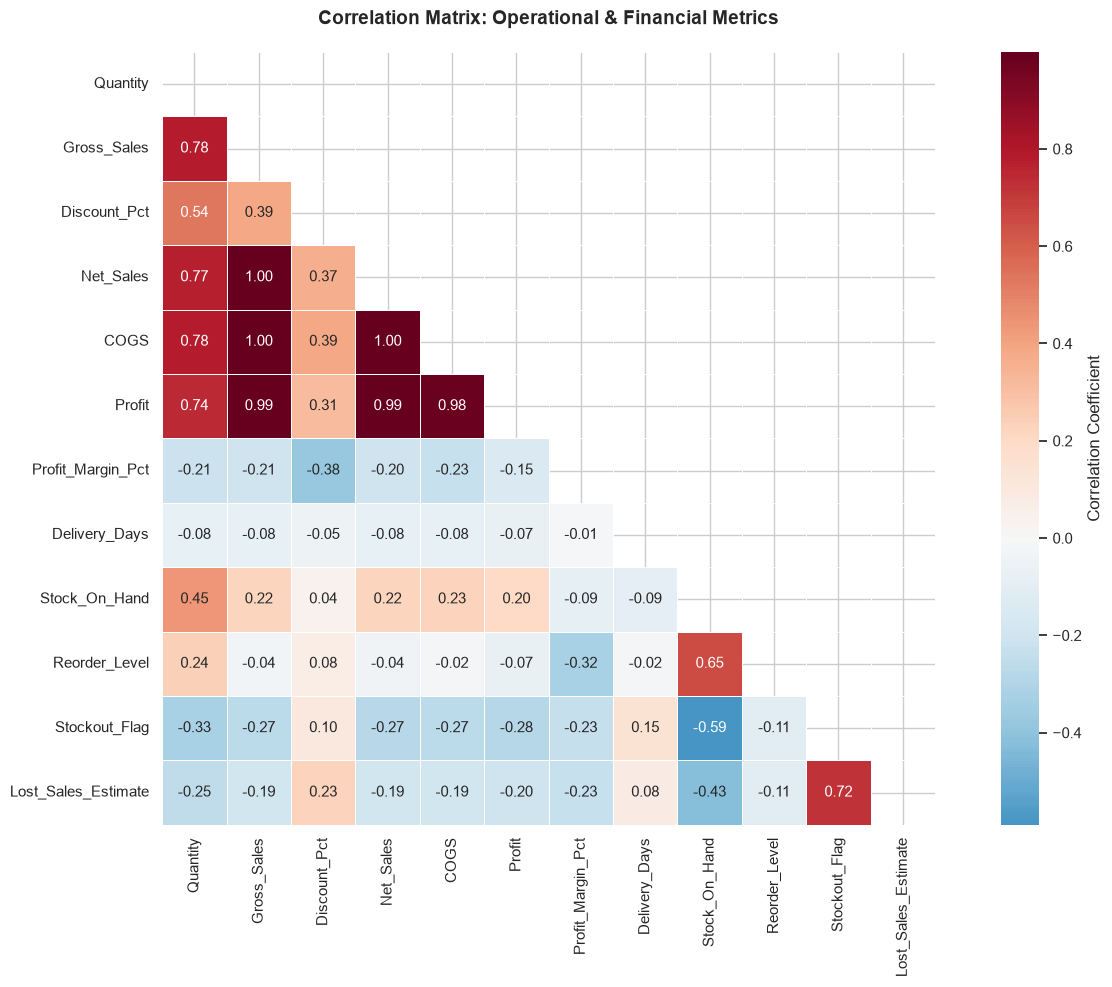


🔗 Strongest Correlations (|r| > 0.3):
               Var1              Var2  Correlation  abs_corr
          Net_Sales       Gross_Sales     0.999315  0.999315
               COGS       Gross_Sales     0.998758  0.998758
               COGS         Net_Sales     0.998011  0.998011
             Profit         Net_Sales     0.992458  0.992458
             Profit       Gross_Sales     0.988995  0.988995
             Profit              COGS     0.982757  0.982757
        Gross_Sales          Quantity     0.781770  0.781770
               COGS          Quantity     0.781507  0.781507
          Net_Sales          Quantity     0.771618  0.771618
             Profit          Quantity     0.743580  0.743580
Lost_Sales_Estimate     Stockout_Flag     0.718739  0.718739
      Reorder_Level     Stock_On_Hand     0.648471  0.648471
      Stockout_Flag     Stock_On_Hand    -0.589459  0.589459
       Discount_Pct          Quantity     0.536765  0.536765
      Stock_On_Hand          Quantity     0.44

In [7]:
# Correlation heatmap of key operational metrics
corr_cols = ['Quantity', 'Gross_Sales', 'Discount_Pct', 'Net_Sales', 'COGS',
             'Profit', 'Profit_Margin_Pct', 'Delivery_Days', 'Stock_On_Hand',
             'Reorder_Level', 'Stockout_Flag', 'Lost_Sales_Estimate']

corr_matrix = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(14, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, square=True, linewidths=0.5, ax=ax,
            cbar_kws={'label': 'Correlation Coefficient'})
ax.set_title('Correlation Matrix: Operational & Financial Metrics', pad=20)
plt.tight_layout()
plt.savefig('../reports/figures/correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

# Print strongest correlations (excluding self-correlations)
print('\n🔗 Strongest Correlations (|r| > 0.3):')
upper = corr_matrix.where(mask == False)
strong = upper.stack().reset_index()
strong.columns = ['Var1', 'Var2', 'Correlation']
strong = strong[strong['Var1'] != strong['Var2']]
strong['abs_corr'] = strong['Correlation'].abs()
print(strong[strong['abs_corr'] > 0.3].sort_values('abs_corr', ascending=False).to_string(index=False))

---
## 4. Pareto Analysis (80/20 Rule)

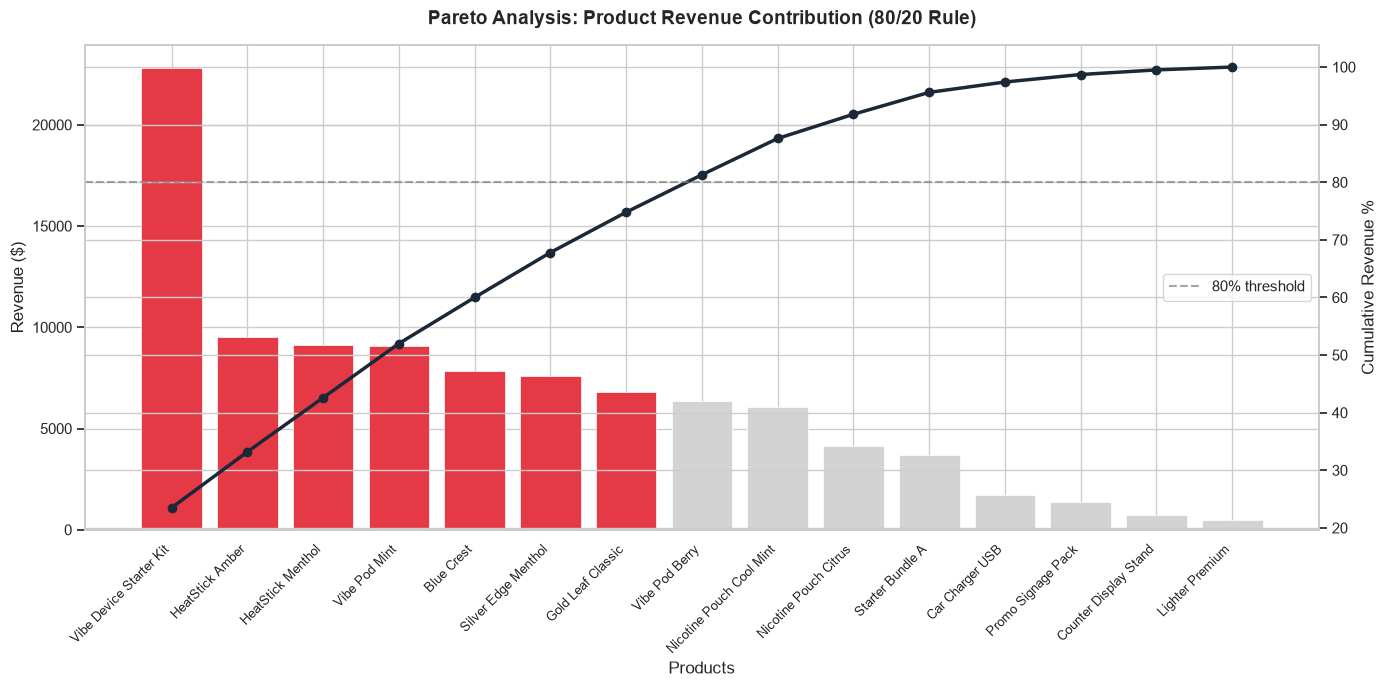


💡 Pareto Finding: 8 out of 15 products (53%) generate 80%+ of revenue.
   This confirms heavy revenue concentration risk.

📊 Revenue Breakdown:
            Product_Name  Net_Sales  Revenue_Pct  Cumulative_Pct
 Vibe Device Starter Kit   22802.12         23.5            23.5
         HeatStick Amber    9502.68          9.8            33.2
       HeatStick Menthol    9139.24          9.4            42.6
           Vibe Pod Mint    9069.00          9.3            52.0
              Blue Crest    7831.59          8.1            60.0
     Silver Edge Menthol    7584.05          7.8            67.8
       Gold Leaf Classic    6791.72          7.0            74.8
          Vibe Pod Berry    6365.75          6.5            81.3
Nicotine Pouch Cool Mint    6058.20          6.2            87.6
   Nicotine Pouch Citrus    4138.74          4.3            91.8
        Starter Bundle A    3671.46          3.8            95.6
         Car Charger USB    1699.63          1.7            97.4
      Prom

In [8]:
# Product-level Pareto analysis
product_rev = (df.groupby('Product_Name')['Net_Sales'].sum()
               .sort_values(ascending=False)
               .reset_index())
product_rev['Cumulative_Revenue'] = product_rev['Net_Sales'].cumsum()
product_rev['Cumulative_Pct'] = (product_rev['Cumulative_Revenue'] / product_rev['Net_Sales'].sum() * 100).round(1)
product_rev['Revenue_Pct'] = (product_rev['Net_Sales'] / product_rev['Net_Sales'].sum() * 100).round(1)

fig, ax1 = plt.subplots(figsize=(14, 7))

# Bars
bars = ax1.bar(range(len(product_rev)), product_rev['Net_Sales'],
               color=[COLORS['accent'] if pct <= 80 else '#D3D3D3'
                      for pct in product_rev['Cumulative_Pct']],
               edgecolor='white', linewidth=0.5)
ax1.set_ylabel('Revenue ($)', fontsize=12)
ax1.set_xlabel('Products', fontsize=12)

# Cumulative line
ax2 = ax1.twinx()
ax2.plot(range(len(product_rev)), product_rev['Cumulative_Pct'],
         color=COLORS['primary'], marker='o', linewidth=2.5, markersize=6)
ax2.axhline(y=80, color='gray', linestyle='--', alpha=0.7, label='80% threshold')
ax2.set_ylabel('Cumulative Revenue %', fontsize=12)
ax2.legend(loc='center right')

ax1.set_xticks(range(len(product_rev)))
ax1.set_xticklabels(product_rev['Product_Name'], rotation=45, ha='right', fontsize=9)
ax1.set_title('Pareto Analysis: Product Revenue Contribution (80/20 Rule)', pad=15)

# Find the 80% cutoff
cutoff_idx = product_rev[product_rev['Cumulative_Pct'] >= 80].index[0]
products_for_80 = cutoff_idx + 1

plt.tight_layout()
plt.savefig('../reports/figures/pareto_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'\n💡 Pareto Finding: {products_for_80} out of {len(product_rev)} products '
      f'({products_for_80/len(product_rev)*100:.0f}%) generate 80%+ of revenue.')
print(f'   This confirms heavy revenue concentration risk.')
print(f'\n📊 Revenue Breakdown:')
print(product_rev[['Product_Name', 'Net_Sales', 'Revenue_Pct', 'Cumulative_Pct']].to_string(index=False))

---
## 5. Regional Performance Deep-Dive

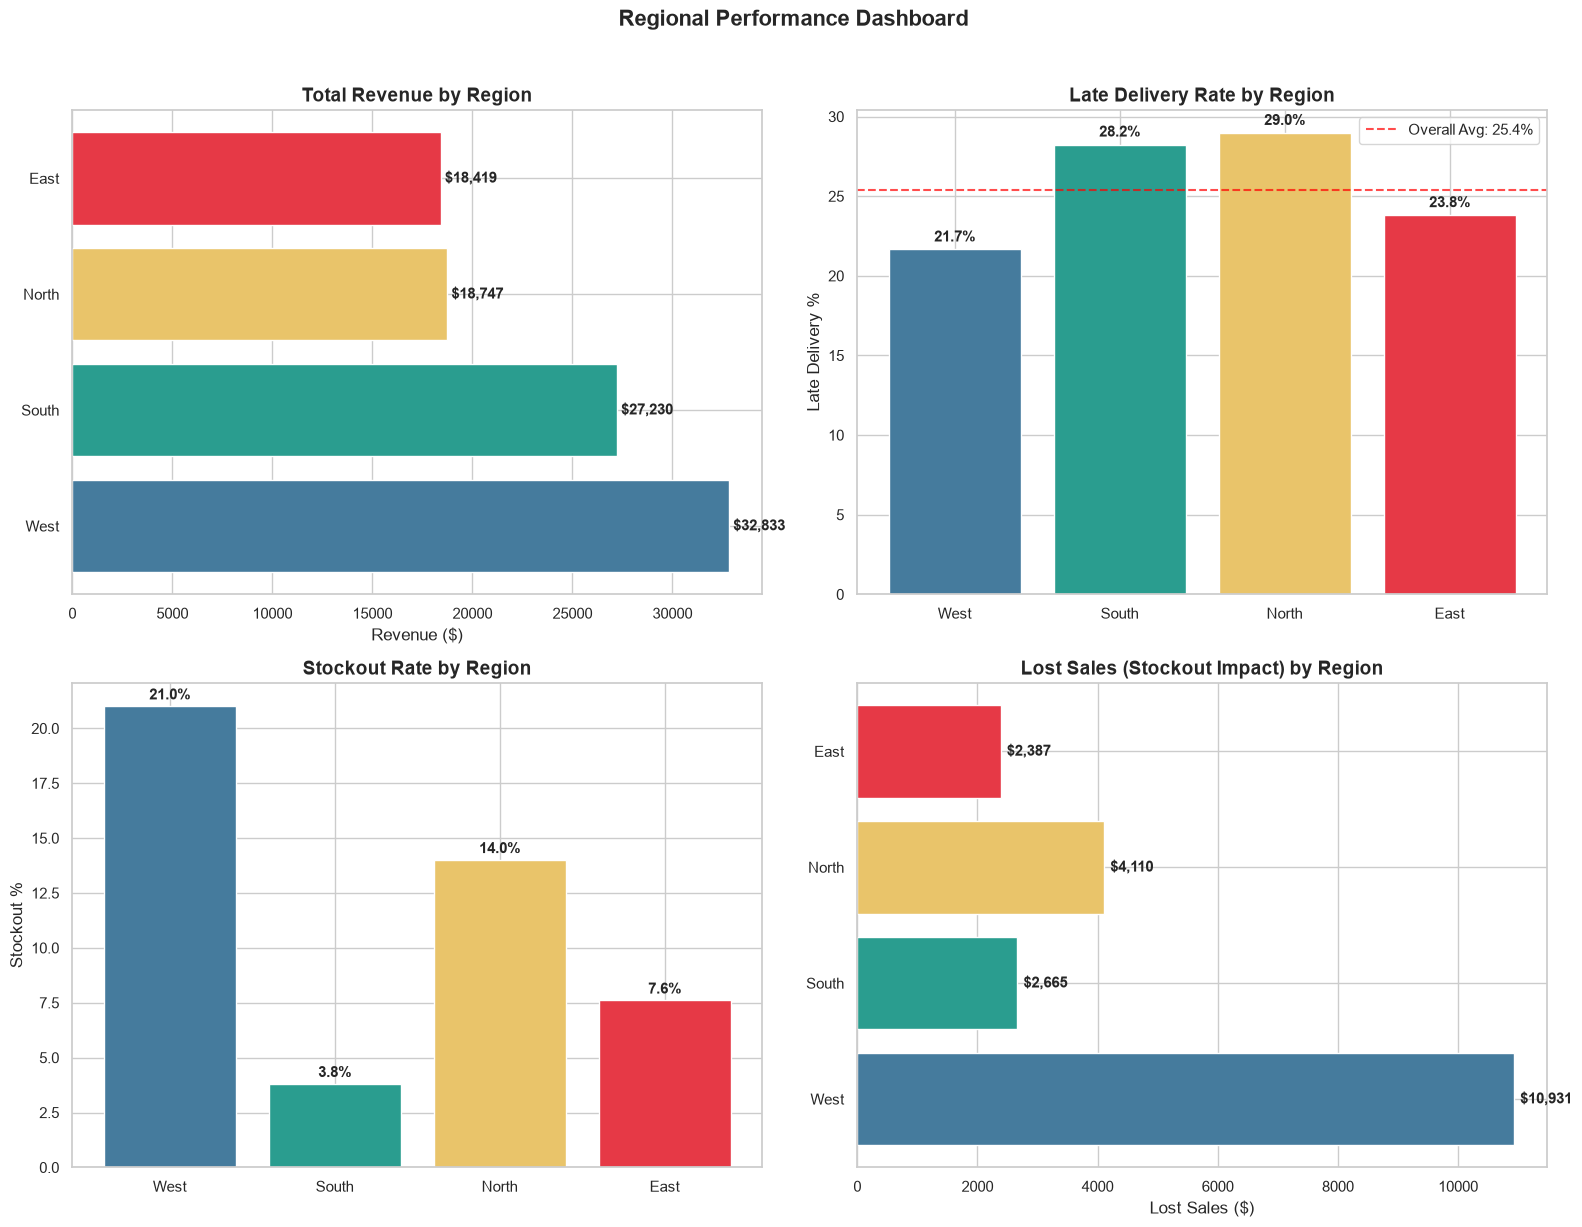

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Regional Performance Dashboard', fontsize=16, fontweight='bold', y=1.02)

region_order = df.groupby('Region')['Net_Sales'].sum().sort_values(ascending=False).index
region_colors = [COLORS['info'], COLORS['success'], COLORS['warning'], COLORS['accent']]

# 1. Revenue by Region
region_rev = df.groupby('Region')['Net_Sales'].sum().reindex(region_order)
axes[0, 0].barh(region_rev.index, region_rev.values, color=region_colors, edgecolor='white')
for i, (val, region) in enumerate(zip(region_rev.values, region_rev.index)):
    axes[0, 0].text(val + 200, i, f'${val:,.0f}', va='center', fontweight='bold')
axes[0, 0].set_title('Total Revenue by Region')
axes[0, 0].set_xlabel('Revenue ($)')

# 2. Late Delivery Rate by Region
late_rate = (df.groupby('Region')['Delivery_Status']
             .apply(lambda x: (x == 'Late').mean() * 100)
             .reindex(region_order))
bars = axes[0, 1].bar(late_rate.index, late_rate.values, color=region_colors, edgecolor='white')
axes[0, 1].axhline(y=25.4, color='red', linestyle='--', alpha=0.7, label='Overall Avg: 25.4%')
for bar, val in zip(bars, late_rate.values):
    axes[0, 1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                    f'{val:.1f}%', ha='center', fontweight='bold')
axes[0, 1].set_title('Late Delivery Rate by Region')
axes[0, 1].set_ylabel('Late Delivery %')
axes[0, 1].legend()

# 3. Stockout Rate by Region
stockout_rate = (df.groupby('Region')['Stockout_Flag']
                 .mean().reindex(region_order) * 100)
bars = axes[1, 0].bar(stockout_rate.index, stockout_rate.values, color=region_colors, edgecolor='white')
for bar, val in zip(bars, stockout_rate.values):
    axes[1, 0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                    f'{val:.1f}%', ha='center', fontweight='bold')
axes[1, 0].set_title('Stockout Rate by Region')
axes[1, 0].set_ylabel('Stockout %')

# 4. Lost Sales by Region
lost = df.groupby('Region')['Lost_Sales_Estimate'].sum().reindex(region_order)
axes[1, 1].barh(lost.index, lost.values, color=region_colors, edgecolor='white')
for i, (val, region) in enumerate(zip(lost.values, lost.index)):
    axes[1, 1].text(val + 100, i, f'${val:,.0f}', va='center', fontweight='bold')
axes[1, 1].set_title('Lost Sales (Stockout Impact) by Region')
axes[1, 1].set_xlabel('Lost Sales ($)')

plt.tight_layout()
plt.savefig('../reports/figures/regional_performance.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 6. Delivery Bottleneck Analysis

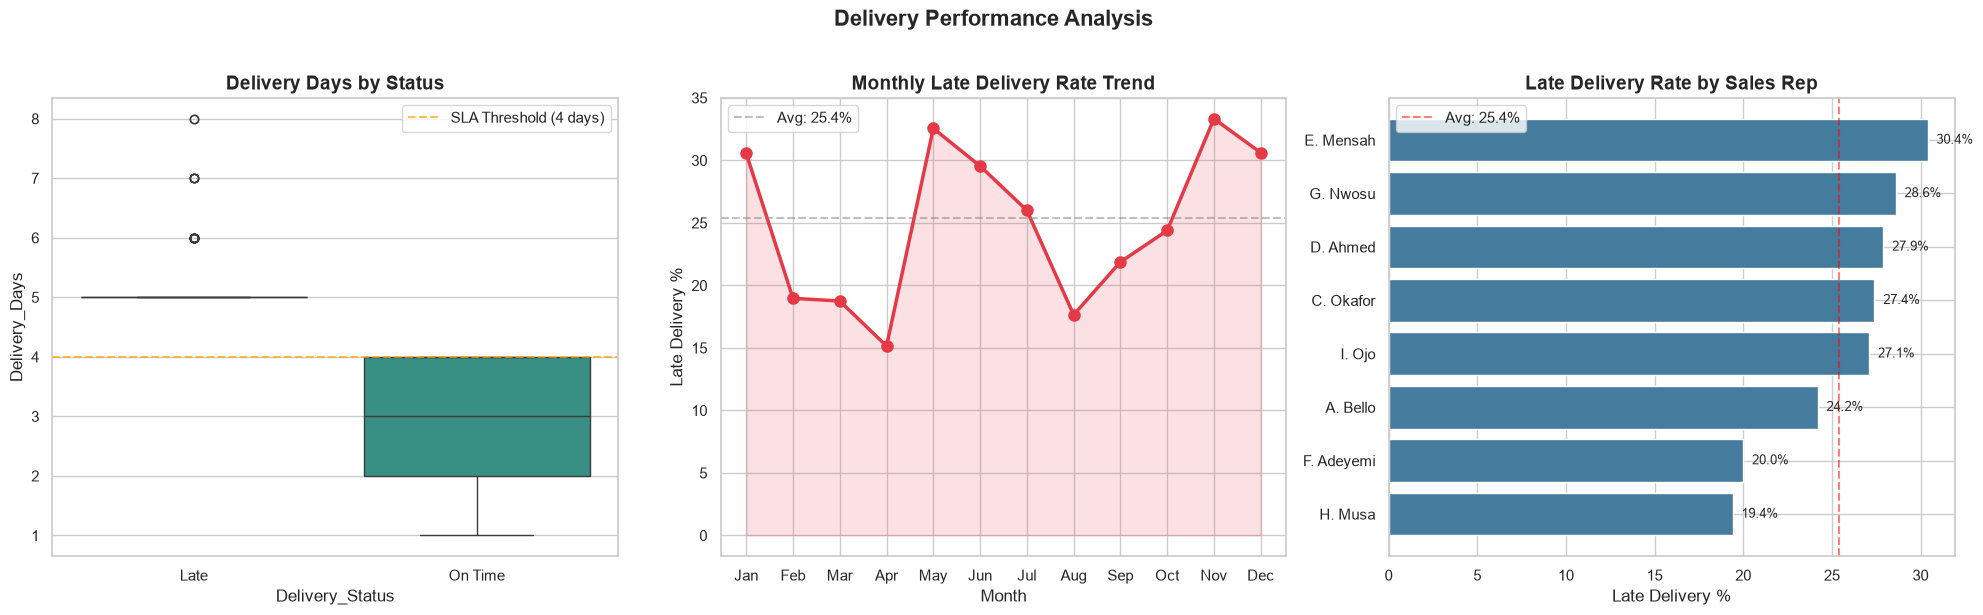

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle('Delivery Performance Analysis', fontsize=16, fontweight='bold', y=1.02)

# 1. Delivery Days Distribution by Status
sns.boxplot(data=df, x='Delivery_Status', y='Delivery_Days', ax=axes[0],
            palette={'On Time': COLORS['success'], 'Late': COLORS['accent']})
axes[0].set_title('Delivery Days by Status')
axes[0].axhline(y=4, color='orange', linestyle='--', alpha=0.7, label='SLA Threshold (4 days)')
axes[0].legend()

# 2. Monthly Late Delivery Trend
monthly_late = (df.groupby('Month')
                .apply(lambda x: (x['Delivery_Status'] == 'Late').mean() * 100)
                .reset_index(name='Late_Pct'))
axes[1].plot(monthly_late['Month'], monthly_late['Late_Pct'],
             marker='o', linewidth=2.5, color=COLORS['accent'], markersize=8)
axes[1].fill_between(monthly_late['Month'], monthly_late['Late_Pct'],
                     alpha=0.15, color=COLORS['accent'])
axes[1].axhline(y=25.4, color='gray', linestyle='--', alpha=0.5, label='Avg: 25.4%')
axes[1].set_title('Monthly Late Delivery Rate Trend')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Late Delivery %')
axes[1].set_xticks(range(1, 13))
axes[1].set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'])
axes[1].legend()

# 3. Late Deliveries by Sales Rep
rep_late = (df.groupby('Sales_Rep')
            .agg(total_orders=('Order_ID', 'count'),
                 late_orders=('Delivery_Status', lambda x: (x == 'Late').sum()))
            .assign(late_pct=lambda x: (x['late_orders'] / x['total_orders'] * 100).round(1))
            .sort_values('late_pct', ascending=True))
axes[2].barh(rep_late.index, rep_late['late_pct'], color=COLORS['info'], edgecolor='white')
for i, (val, rep) in enumerate(zip(rep_late['late_pct'].values, rep_late.index)):
    axes[2].text(val + 0.5, i, f'{val:.1f}%', va='center', fontsize=9)
axes[2].set_title('Late Delivery Rate by Sales Rep')
axes[2].set_xlabel('Late Delivery %')
axes[2].axvline(x=25.4, color='red', linestyle='--', alpha=0.5, label='Avg: 25.4%')
axes[2].legend()

plt.tight_layout()
plt.savefig('../reports/figures/delivery_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 7. Customer Segment Analysis

📊 Customer Segment Performance Summary


,Total_Revenue,Avg_Order_Value,Total_Profit,Avg_Profit_Margin,Total_Orders,Late_Deliveries,Stockout_Count,Lost_Sales,Late_Rate,Revenue_Share
Customer_Segment,,,,,,,,,,
Distributor,31060.73,313.74,10246.43,0.33,99,18,24,13565.21,18.2,31.9
Wholesale,28742.35,319.36,9907.30,0.34,90,30,11,3887.58,33.3,29.6
Retail,20019.96,93.55,7634.51,0.39,214,46,14,814.14,21.5,20.6
Key Account,17406.10,179.44,6230.75,0.36,97,33,12,1826.35,34.0,17.9


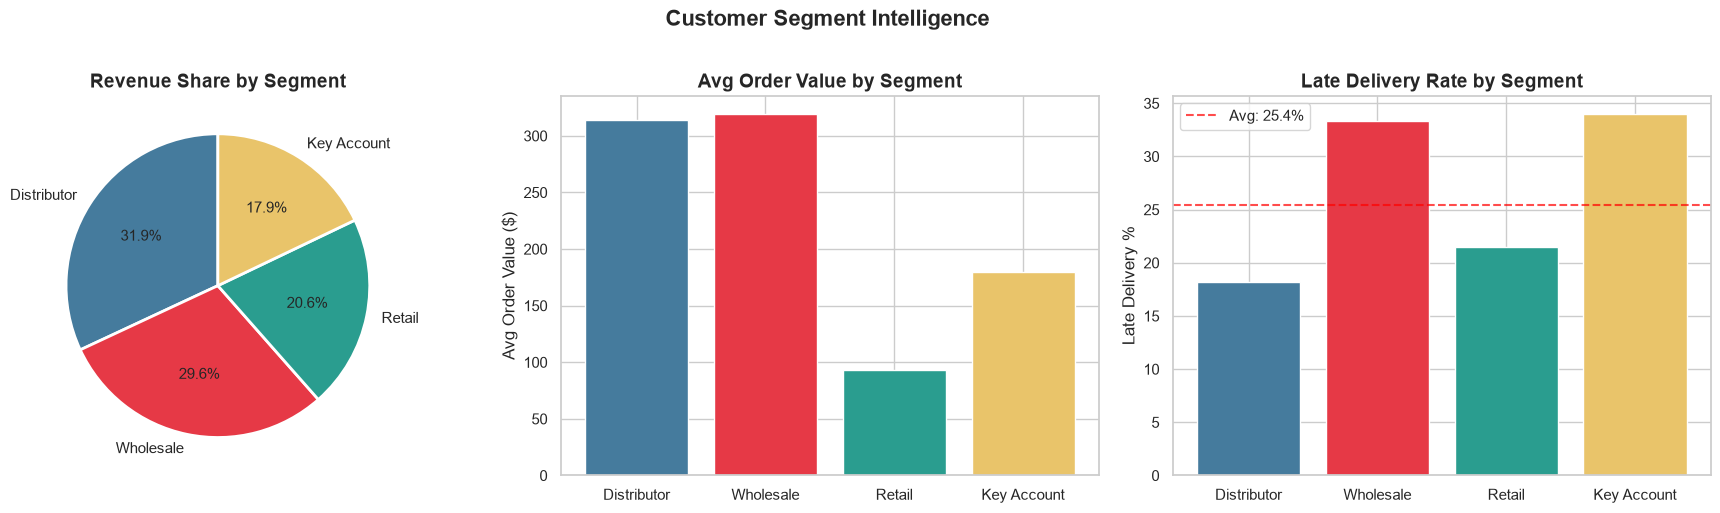

In [11]:
# Customer segment performance summary
segment_analysis = (df.groupby('Customer_Segment')
    .agg(
        Total_Revenue=('Net_Sales', 'sum'),
        Avg_Order_Value=('Net_Sales', 'mean'),
        Total_Profit=('Profit', 'sum'),
        Avg_Profit_Margin=('Profit_Margin_Pct', 'mean'),
        Total_Orders=('Order_ID', 'count'),
        Late_Deliveries=('Delivery_Status', lambda x: (x == 'Late').sum()),
        Stockout_Count=('Stockout_Flag', 'sum'),
        Lost_Sales=('Lost_Sales_Estimate', 'sum')
    )
    .assign(
        Late_Rate=lambda x: (x['Late_Deliveries'] / x['Total_Orders'] * 100).round(1),
        Revenue_Share=lambda x: (x['Total_Revenue'] / x['Total_Revenue'].sum() * 100).round(1)
    )
    .sort_values('Total_Revenue', ascending=False)
)

print('📊 Customer Segment Performance Summary')
print('=' * 80)
display(segment_analysis.round(2))

# Visualization
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Customer Segment Intelligence', fontsize=16, fontweight='bold', y=1.02)

seg_colors = [COLORS['info'], COLORS['accent'], COLORS['success'], COLORS['warning']]

# Revenue share pie
axes[0].pie(segment_analysis['Total_Revenue'], labels=segment_analysis.index,
            autopct='%1.1f%%', colors=seg_colors, startangle=90,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[0].set_title('Revenue Share by Segment')

# Avg order value comparison
axes[1].bar(segment_analysis.index, segment_analysis['Avg_Order_Value'],
            color=seg_colors, edgecolor='white')
axes[1].set_title('Avg Order Value by Segment')
axes[1].set_ylabel('Avg Order Value ($)')

# Late rate by segment
axes[2].bar(segment_analysis.index, segment_analysis['Late_Rate'],
            color=seg_colors, edgecolor='white')
axes[2].axhline(y=25.4, color='red', linestyle='--', alpha=0.7, label='Avg: 25.4%')
axes[2].set_title('Late Delivery Rate by Segment')
axes[2].set_ylabel('Late Delivery %')
axes[2].legend()

plt.tight_layout()
plt.savefig('../reports/figures/customer_segments.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 8. Stockout Impact & Revenue-at-Risk Quantification

💰 REVENUE-AT-RISK ANALYSIS
Actual Revenue:          $   97,229.14
Lost Sales (Stockouts):  $   20,093.28
Potential Revenue:       $  117,322.42
Revenue Leakage Rate:           17.1%

📌 For every $1 earned, $0.21 is lost to stockouts.

📦 Stockout Impact by Product:


,Stockout_Count,Lost_Revenue,Avg_Lost_Per_Stockout
Product_Name,,,
Vibe Device Starter Kit,6,5588.44,931.41
Vibe Pod Mint,6,2403.63,400.60
Vibe Pod Berry,5,2325.75,465.15
Nicotine Pouch Cool Mint,8,2200.64,275.08
Nicotine Pouch Citrus,5,2200.40,440.08
HeatStick Menthol,6,1040.71,173.45
Silver Edge Menthol,6,966.55,161.09
HeatStick Amber,4,943.00,235.75
Starter Bundle A,3,901.80,300.60


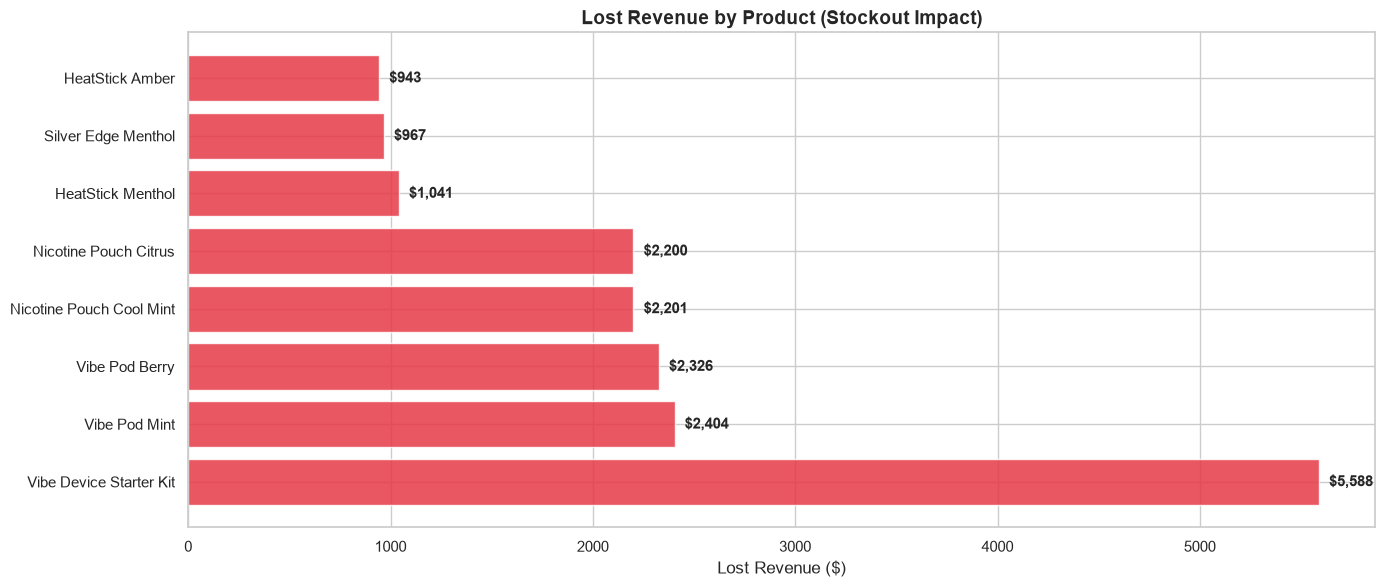

In [12]:
# ============================================================
# REVENUE AT RISK MODEL
# ============================================================
total_revenue = df['Net_Sales'].sum()
total_lost = df['Lost_Sales_Estimate'].sum()
total_potential = total_revenue + total_lost

print('💰 REVENUE-AT-RISK ANALYSIS')
print('=' * 50)
print(f'Actual Revenue:          ${total_revenue:>12,.2f}')
print(f'Lost Sales (Stockouts):  ${total_lost:>12,.2f}')
print(f'Potential Revenue:       ${total_potential:>12,.2f}')
print(f'Revenue Leakage Rate:    {total_lost/total_potential*100:>11.1f}%')
print(f'\n📌 For every $1 earned, ${total_lost/total_revenue:.2f} is lost to stockouts.')

# Stockout analysis by product
stockout_impact = (df[df['Stockout_Flag'] == 1]
    .groupby('Product_Name')
    .agg(
        Stockout_Count=('Stockout_Flag', 'sum'),
        Lost_Revenue=('Lost_Sales_Estimate', 'sum'),
        Avg_Lost_Per_Stockout=('Lost_Sales_Estimate', 'mean')
    )
    .sort_values('Lost_Revenue', ascending=False))

print(f'\n📦 Stockout Impact by Product:')
display(stockout_impact.round(2))

# Waterfall-style visualization
fig, ax = plt.subplots(figsize=(14, 6))
top_stockouts = stockout_impact.head(8)
bars = ax.barh(top_stockouts.index, top_stockouts['Lost_Revenue'],
               color=COLORS['accent'], edgecolor='white', alpha=0.85)
for bar, val in zip(bars, top_stockouts['Lost_Revenue']):
    ax.text(val + 50, bar.get_y() + bar.get_height()/2,
            f'${val:,.0f}', va='center', fontweight='bold')
ax.set_title('Lost Revenue by Product (Stockout Impact)', fontsize=14, fontweight='bold')
ax.set_xlabel('Lost Revenue ($)')
plt.tight_layout()
plt.savefig('../reports/figures/stockout_impact.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 9. Scenario Modeling: What-If Analysis

In [13]:
# What-if: Impact of reducing stockout rate
print('📊 SCENARIO ANALYSIS: Reducing Stockout Rate')
print('=' * 60)

current_stockout_rate = df['Stockout_Flag'].mean()
current_lost_sales = df['Lost_Sales_Estimate'].sum()

scenarios = [0.02, 0.04, 0.06, 0.08, 0.10]  # target stockout rates
scenario_results = []

for target_rate in scenarios:
    reduction_factor = target_rate / current_stockout_rate
    projected_lost = current_lost_sales * reduction_factor
    recovered = current_lost_sales - projected_lost
    scenario_results.append({
        'Target_Stockout_Rate': f'{target_rate*100:.0f}%',
        'Reduction_from_Current': f'{(current_stockout_rate - target_rate)*100:.1f}pp',
        'Projected_Lost_Sales': f'${projected_lost:,.0f}',
        'Revenue_Recovered': f'${recovered:,.0f}',
        'Recovery_Rate': f'{recovered/current_lost_sales*100:.1f}%'
    })

scenario_df = pd.DataFrame(scenario_results)
print(f'Current Stockout Rate: {current_stockout_rate*100:.1f}%')
print(f'Current Lost Sales:    ${current_lost_sales:,.0f}')
print(f'\nProjected Recovery by Scenario:')
display(scenario_df)

print(f'\n💡 Key Insight: Reducing stockout rate from {current_stockout_rate*100:.1f}% to 6% '
      f'could recover ~${current_lost_sales * (1 - 0.06/current_stockout_rate):,.0f} in annual revenue.')

📊 SCENARIO ANALYSIS: Reducing Stockout Rate
Current Stockout Rate: 12.2%
Current Lost Sales:    $20,093

Projected Recovery by Scenario:


,Target_Stockout_Rate,Reduction_from_Current,Projected_Lost_Sales,Revenue_Recovered,Recovery_Rate
0,2%,10.2pp,"$3,294","$16,799",83.6%
1,4%,8.2pp,"$6,588","$13,505",67.2%
2,6%,6.2pp,"$9,882","$10,211",50.8%
3,8%,4.2pp,"$13,176","$6,917",34.4%
4,10%,2.2pp,"$16,470","$3,623",18.0%



💡 Key Insight: Reducing stockout rate from 12.2% to 6% could recover ~$10,211 in annual revenue.


---
## 10. Monthly Revenue Trend & Seasonality

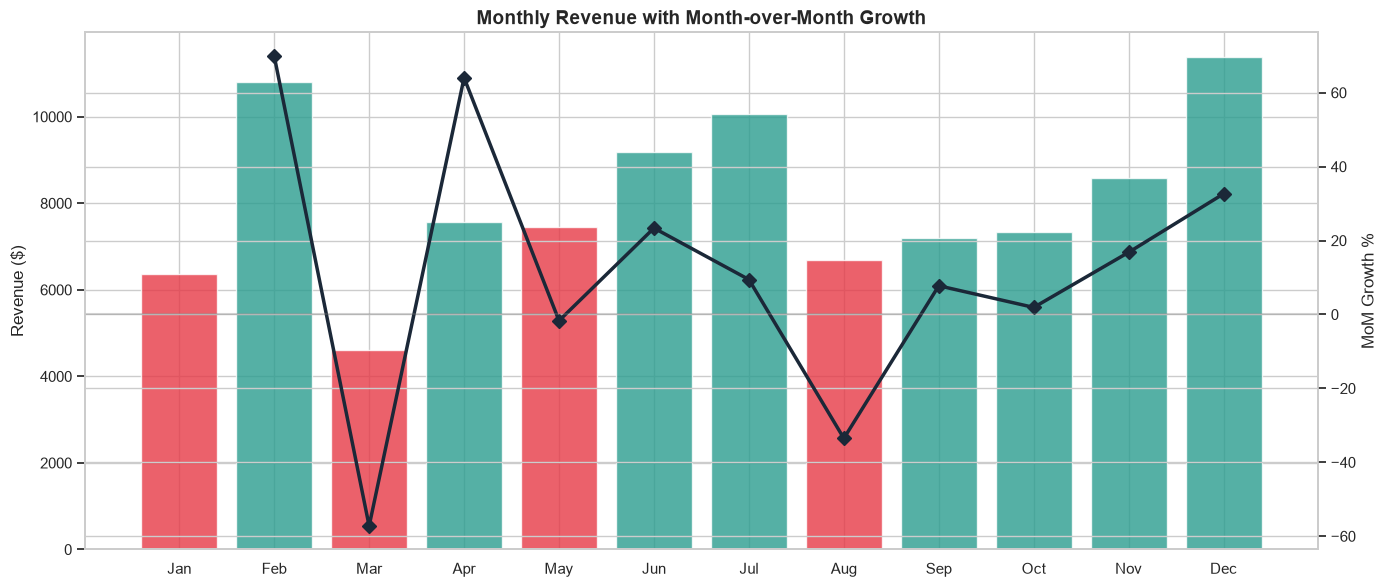

📊 Monthly Performance Summary:


,Month_Name,Revenue,Orders,Avg_Order_Value,MoM_Growth,Late_Count,Lost_Sales
0,Jan,6354.32,36,176.51,NaN,11,1898.19
1,Feb,10797.95,58,186.17,69.93,11,712.03
2,Mar,4618.45,32,144.33,-57.23,6,2616.75
3,Apr,7576.60,33,229.59,64.05,5,1935.67
4,May,7448.45,43,173.22,-1.69,14,572.31
5,Jun,9189.31,44,208.85,23.37,13,803.00
6,Jul,10057.21,50,201.14,9.44,13,1448.50
7,Aug,6686.02,34,196.65,-33.52,6,1326.72
8,Sep,7204.91,32,225.15,7.76,7,671.38
9,Oct,7342.16,41,179.08,1.90,10,1316.60


In [14]:
# Monthly trend with MoM growth
monthly = (df.groupby('Month')
           .agg(Revenue=('Net_Sales', 'sum'),
                Orders=('Order_ID', 'count'),
                Avg_Order_Value=('Net_Sales', 'mean'),
                Late_Count=('Delivery_Status', lambda x: (x == 'Late').sum()),
                Lost_Sales=('Lost_Sales_Estimate', 'sum'))
           .reset_index())

monthly['MoM_Growth'] = monthly['Revenue'].pct_change() * 100
monthly['Month_Name'] = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']

fig, ax1 = plt.subplots(figsize=(14, 6))

# Revenue bars
bars = ax1.bar(monthly['Month_Name'], monthly['Revenue'],
               color=[COLORS['success'] if g > 0 else COLORS['accent']
                      for g in monthly['MoM_Growth'].fillna(0)],
               edgecolor='white', alpha=0.8)
ax1.set_ylabel('Revenue ($)', fontsize=12)

# MoM growth line
ax2 = ax1.twinx()
ax2.plot(monthly['Month_Name'], monthly['MoM_Growth'],
         color=COLORS['primary'], marker='D', linewidth=2.5, markersize=7)
ax2.set_ylabel('MoM Growth %', fontsize=12)
ax2.axhline(y=0, color='gray', linestyle='-', alpha=0.3)

ax1.set_title('Monthly Revenue with Month-over-Month Growth', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/figures/monthly_trend.png', dpi=150, bbox_inches='tight')
plt.show()

# Summary table
print('📊 Monthly Performance Summary:')
display(monthly[['Month_Name', 'Revenue', 'Orders', 'Avg_Order_Value', 'MoM_Growth', 'Late_Count', 'Lost_Sales']].round(2))

---
## 11. Key Findings Summary

### Financial Impact
| Finding | Impact |
|---------|--------|
| Stockout-driven revenue leakage | **$20,093** lost (20.7% of potential revenue) |
| Revenue concentration in Vapes | 1 category = **39%** of total revenue |
| Discount erosion | Average 5.2% discount reduces gross by **$6,714** annually |

### Operational Bottlenecks
| Finding | Impact |
|---------|--------|
| Late delivery rate | **25.4%** — 1 in 4 orders delivered late |
| South region delivery crisis | **28.2%** late rate (worst) despite being #2 in revenue |
| North region delivery crisis | **29.0%** late rate with lowest revenue |

### Recommendations
1. **Reduce stockout rate to 6%** → recover ~$10K in annual revenue
2. **Prioritize South region logistics** → highest revenue-at-risk from delivery failures
3. **Diversify product portfolio** → reduce dependency on Vapes category
4. **Review discount strategy** → optimize margin without impacting volume